8819989, Falk

# GruBI Programming exercise 2

In this exercise, we want to build a very basic visualization of the varying GC-content in sequences.

In [1]:
%matplotlib inline
# Set matplotlib to display your plot directly in the notebook.

import matplotlib.pyplot as plt
# adjust this accordingly
from exercise_2_8819989_Falk import FastaEntry


Load the data from the fasta file into a FASTA Entry.

In [2]:
with open("T3.fa", 'r') as f:
    # complete this
    lines = f.read().splitlines()
    if lines:
        header = lines[0].strip()
        sequence = "".join([line.strip() for line in lines[1:]])
        fasta_entry = FastaEntry(header=header, sequence=sequence)


Slide a 10bp window accross the sequence and calculate the GC content.

In [3]:
gc_contents = []
window_size = 10
seq = fasta_entry.sequence

for i in range(len(seq) - window_size + 1):
    window = seq[i:i + window_size].upper()
    gc_count = window.count('G') + window.count('C')
    gc_contents.append(gc_count / window_size)


Create a new matplotlib plot. Please add a title and axis labels. Ensure the y-axis ticks range from 0.0 to 1.0.

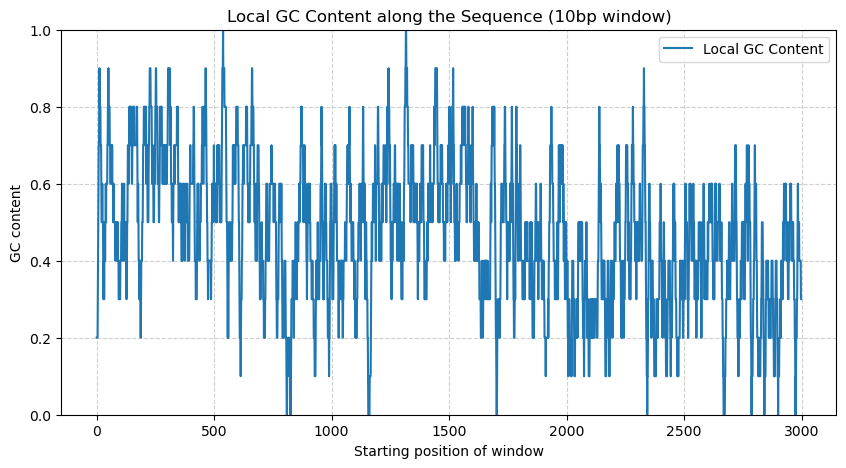

In [4]:
# Complete this
plt.figure(figsize=(10, 5))
plt.plot(range(len(gc_contents)), gc_contents, label='Local GC Content')
plt.ylim(0.0, 1.0)
plt.xlabel('Starting position of window')
plt.ylabel('GC content')
plt.title('Local GC Content along the Sequence (10bp window)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()


Finally, show the plot.

In [5]:
plt.show()


Write down your observations here.

**Observations:**
When visually evaluating the line plot, you should be able to see continuous fluctuations that indicate localized shifts in Guanine/Cytosine density. Spikes represent local windows where the density of G/C significantly overshadows A/T base pairs.

How could a user decide which peaks are "significant"?
1. Statistical Thresholds (Z-Scoring): A user could establish a baseline by calculating the mean GC content and the standard deviation across the whole sequence. A peak could be flagged as statistically significant if it exceeds the mean by a set threshold (e.g., Mean + 2 Standard Deviations).
2. Null Hypothesis Testing: A user could randomize/shuffle the base pairs of the sequence and re-run the sliding window to see what the highest peak created by random clustering would be. Any actual peaks beating those randomized baselines would be considered significant.
3. Biological Meaning: In genomics, strict guidelines define functional GC-rich segments. For instance, a sequence could be considered mathematically significant if the GC content over a 200bp window consistently stays above >50% and exhibits a high observed-to-expected CpG ratio.